# Options for speed of the cohesive coupons: same curves, less time

The coupons of [`delamination.create_coupon`](../cohesive_zone_mixed_mode.rst) assemble and factorize the tangent
stiffness matrix at every Newton-Raphson iteration. Three options, all off by default, reduce the time of an
analysis without changing its results beyond the round-off
(see [Options for speed](../cohesive_zone_mixed_mode.rst) and [Plate kernels as matrix products](../plate_blas.rst)):

- `plate_kernels='blas'` of [`MultiDomain`](../multidomain.rst) and `create_coupon`: the plate matrices and vectors
  of `plate_clpt_donnell` and `plate_fsdt_donnell` as products of dense matrices with operators tabulated once per
  domain, [`panels.multidomain.plate_blas`](../plate_blas.rst);
- `reuse_kT=True` of `solve_coupon` and `MultiDomain.get_reduced_functions`: the load vector of the prescribed
  displacement from the tangent already assembled at the same configuration;
- `linear_solver='pardiso_lu'` (oneMKL) or `'dense_lu'` of `structsolve>=0.13.0`, forwarded by `solve_coupon` to
  `structsolve.Analysis`.

This notebook

1. compares, for one domain of the size of the cohesive domains of the coupons, the matrices and vectors of the
   Cython kernels and of `plate_kernels='blas'`, and the time of both;
2. runs a DCB coupon with the defaults and with the options on, and compares the increments, the Newton-Raphson
   iterations, the load-displacement curves and the run times.

The times are those of the machine that ran the notebook, printed below; they depend on its CPU and BLAS library,
the equality of the results does not.

In [1]:
%matplotlib inline
import os
import platform
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import structsolve
import panels
from panels.shell import Shell
from panels.multidomain import MultiDomain
from panels.multidomain.delamination import create_coupon, solve_coupon
from panels.multidomain.connections.czm import BilinearLaw


def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '---|'*len(headers)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def rel(A, B):
    A = A.toarray() if hasattr(A, 'toarray') else np.asarray(A)
    B = B.toarray() if hasattr(B, 'toarray') else np.asarray(B)
    return np.abs(A - B).max()/np.abs(B).max()


def median_time(func, repeat=5):
    func()  # warm-up, also builds the operators of 'blas'
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        func()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def linear_solver():
    '''pardiso_lu with oneMKL, else dense_lu, when structsolve has them'''
    try:
        from structsolve.static import LINEAR_SOLVERS
    except ImportError:
        return None
    if 'pardiso_lu' in LINEAR_SOLVERS:
        try:
            from structsolve.pardiso import load_mkl
            load_mkl()
            return 'pardiso_lu'
        except Exception:
            pass
    return 'dense_lu' if 'dense_lu' in LINEAR_SOLVERS else None


from structsolve.static import LINEAR_SOLVERS
print('panels', panels.__version__, '| structsolve linear solvers', LINEAR_SOLVERS, '| numpy', np.__version__)
print(platform.processor(), '|', os.cpu_count(), 'logical CPUs')
SOLVER = linear_solver()
print('linear solver of the options:', SOLVER)

panels 0.17.0 | structsolve linear solvers ('splu', 'pardiso', 'pardiso_lu', 'dense_lu') | numpy 2.4.4
AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | 16 logical CPUs
linear solver of the options: pardiso_lu


## 1. One domain: Cython kernels against `plate_kernels='blas'`

A domain of $20 \times 25.4$ mm, $[0]_{12}$ AS4/PEEK, $m = 15$, $n = 6$ terms and $60 \times 10$ Gauss-Legendre
points, as the cohesive domains of the coupons, at a random configuration: the tangent ($K_C$ and $K_G$ with
`NLgeom=True`), the internal force vector and the product of the tangent by a vector, assembled with
`MultiDomain([p], conn=[])` and either option.

In [2]:
LAM = (122700., 10100., 0.25, 5500., 5500., 3700.)  # AS4/PEEK, Camanho et al. (2003), Table 1


def one_domain(model, kernels):
    p = Shell(model=model, a=20., b=25.4, m=15, n=6, stack=[0]*12, plyt=0.13, laminaprop=LAM)
    p.nx, p.ny = 60, 10
    return MultiDomain([p], conn=[], plate_kernels=kernels)


rows = []
for model in ('plate_clpt_donnell', 'plate_fsdt_donnell'):
    mds = {k: one_domain(model, k) for k in ('cython', 'blas')}
    rng = np.random.default_rng(0)
    c = 1e-2*rng.standard_normal(mds['cython'].get_size())
    v = rng.standard_normal(c.size)
    res, times = {}, {}
    for k, md_ in mds.items():
        res[k] = dict(kC=md_.calc_kC(c=c, NLgeom=True, silent=True),
                      kG=md_.calc_kG(c=c, NLgeom=True, silent=True),
                      fint=md_.calc_fint(c), kTv=md_.calc_kTv(c, v))
        times[k] = median_time(lambda: (md_.calc_kC(c=c, NLgeom=True, silent=True),
                                        md_.calc_kG(c=c, NLgeom=True, silent=True),
                                        md_.calc_fint(c)))
    rows.append(['`%s`' % model] + ['%.1e' % rel(res['blas'][k], res['cython'][k]) for k in res['blas']]
                + ['%.3f' % times['cython'], '%.3f' % times['blas'], '%.1f' % (times['cython']/times['blas'])])
table(['model', '$K_C$', '$K_G$', '$F_{int}$', '$K_T v$', 'Cython (s)', 'blas (s)', 'speed-up'], rows)

| model | $K_C$ | $K_G$ | $F_{int}$ | $K_T v$ | Cython (s) | blas (s) | speed-up |
|---|---|---|---|---|---|---|---|
| `plate_clpt_donnell` | 3.6e-15 | 4.8e-15 | 2.8e-15 | 4.2e-15 | 0.071 | 0.017 | 4.2 |
| `plate_fsdt_donnell` | 5.1e-15 | 6.0e-15 | 3.0e-15 | 3.8e-15 | 0.124 | 0.037 | 3.3 |

The columns $K_C$ to $K_T v$ are the largest difference over the largest entry: the round-off. The times are those
of one tangent and one internal force vector, $K_C + K_G + F_{int}$, the median of 5 evaluations.

## 2. A DCB coupon with the options off and on

The DCB of AS4/PEEK, $25.4$ mm wide, arms of $[0]_{12}$, $0.13$ mm plies, $a_0 = 30$ mm, $60$ mm long, with the
bilinear law of the tests of the coupons (used for verification only), CLPT, three cohesive domains of 15 terms over
the first $15$ mm of the bonded length, up to an opening $\delta = 3$ mm, past the onset of the damage, in increments
of $0.25$ mm. The Newton-Raphson iterations of each increment are counted as the evaluations of the tangent.

In [3]:
def dcb(on, **analysis_kw):
    law = BilinearLaw(0.969, 1.719, 80., 100., 1e5, 2.284)
    md_, info = create_coupon('DCB', LAM, 0.13, [0]*12, 25.4, 30., [law], x_end=60., nd=3, L_coh=15.,
                              m_crack=10, m_coh=15, m_far=10, n=6, nr_y_gauss=6,
                              plate_kernels='blas' if on else 'cython')
    calls = []
    calc_kC = md_.calc_kC

    def counted(*args, **kwargs):
        calls.append(1)
        return calc_kC(*args, **kwargs)
    md_.calc_kC = counted
    ends = []
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res, an = solve_coupon(md_, info, 3., initialInc=0.25, maxInc=0.25, reuse_kT=on,
                               record=lambda an, c, row: ends.append(len(calls)), **analysis_kw)
    res['time'] = time.perf_counter() - t0
    res['iterations'] = np.diff([0] + ends)
    return res


runs = {'defaults': dcb(False), "plate_kernels='blas', reuse_kT=True": dcb(True)}
if SOLVER is not None:
    runs["plate_kernels='blas', reuse_kT=True, linear_solver='%s'" % SOLVER] = dcb(True, linear_solver=SOLVER)
ref = runs['defaults']
rows = []
for name, r in runs.items():
    rows.append([name, len(r['delta']), np.array_equal(r['delta'], ref['delta']),
                 np.array_equal(r['iterations'], ref['iterations']), int(r['iterations'].sum()),
                 '%.1e' % np.abs(r['P'] - ref['P']).max(), '%.1f' % r['time'], '%.2f' % (ref['time']/r['time'])])
table(['options', 'increments', 'same $\\delta$', 'same iterations', 'iterations', 'max $\\lvert \\Delta P \\rvert$ (N)',
       'time (s)', 'speed-up'], rows)
print('largest damage variable at the end: %.3f' % ref['max_d'][-1])

| options | increments | same $\delta$ | same iterations | iterations | max $\lvert \Delta P \rvert$ (N) | time (s) | speed-up |
|---|---|---|---|---|---|---|---|
| defaults | 12 | True | True | 26 | 0.0e+00 | 26.5 | 1.00 |
| plate_kernels='blas', reuse_kT=True | 12 | True | True | 26 | 2.9e-11 | 14.4 | 1.84 |
| plate_kernels='blas', reuse_kT=True, linear_solver='pardiso_lu' | 12 | True | True | 26 | 1.8e-11 | 10.8 | 2.45 |

largest damage variable at the end: 0.976


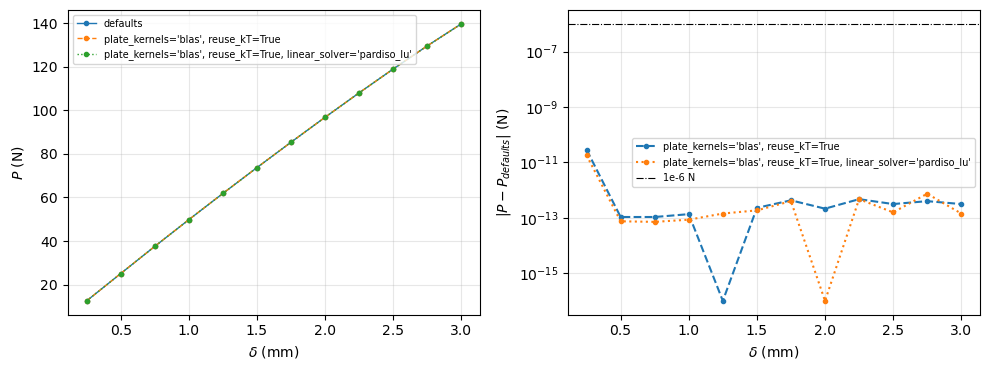

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (name, r), ls in zip(runs.items(), ('-', '--', ':')):
    axes[0].plot(r['delta'], r['P'], ls, marker='o', ms=3, lw=1, label=name)
    if r is not ref:
        axes[1].semilogy(r['delta'], np.maximum(np.abs(r['P'] - ref['P']), 1e-16), ls, marker='o', ms=3,
                         label=name)
axes[0].set_xlabel(r'$\delta$ (mm)')
axes[0].set_ylabel('$P$ (N)')
axes[0].legend(fontsize=7)
axes[1].axhline(1e-6, color='k', lw=0.8, ls='-.', label='1e-6 N')
axes[1].set_xlabel(r'$\delta$ (mm)')
axes[1].set_ylabel(r'$|P - P_{defaults}|$ (N)')
axes[1].legend(fontsize=7)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The options give the same increments and the same iterations as the defaults, and loads that differ by the
round-off, far below $10^{-6}$ N; the curves overlap. The speed-up grows with the number of terms and of points of the
cohesive domains, whose plate kernels dominate the time with the defaults, and the faster factorizations matter once
the plate kernels are fast. `tests/multidomain/test_plate_blas.py` checks the same equalities on a smaller DCB.